# Notebook 02: PyTorch Dataset & DataLoader

In this notebook, we build the **data feeding pipeline** for our deep learning model:
1. **`ColorizationDataset`**: Loads images, resizes to $256\times256$, applies data augmentation, converts to CIE Lab, and normalizes to $[-1, 1]$.
2. **`DataLoader`**: Batches images together (Batch size = 16) and enables fast GPU pre-fetching.
3. **Batch Inspection**: Verify tensor dimensions and visualize the reconstructed color images directly from the dataloader.

### 1. Import Libraries

In [1]:
import os
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import color
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### 2. Gather Image Filepaths

In [2]:
train_dir = os.path.join("..", "data", "raw", "train")
val_dir = os.path.join("..", "data", "raw", "val")

train_paths = [os.path.join(train_dir, f) for f in os.listdir(train_dir) if f.endswith((".jpg", ".png"))]
val_paths = [os.path.join(val_dir, f) for f in os.listdir(val_dir) if f.endswith((".jpg", ".png"))]

print(f"Total training images  : {len(train_paths)}")
print(f"Total validation images: {len(val_paths)}")

Total training images  : 2000
Total validation images: 200


### 3. Define the `ColorizationDataset` Class

- **Augmentation (Train only):** Random horizontal flip ($p=0.5$).
- **Size:** Resized to $256\times256$ using bicubic interpolation.
- **Output Shapes:**
  - `L`: `(1, 256, 256)` normalized to $[-1, 1]$
  - `ab`: `(2, 256, 256)` normalized to $[-1, 1]$

In [3]:
class ColorizationDataset(Dataset):
    def __init__(self, paths, is_train=True):
        self.paths = paths
        self.is_train = is_train
        
        if self.is_train:
            self.transforms = T.Compose([
                T.Resize((256, 256), Image.BICUBIC),
                T.RandomHorizontalFlip(p=0.5)
            ])
        else:
            self.transforms = T.Compose([
                T.Resize((256, 256), Image.BICUBIC)
            ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        # 1. Load image and ensure RGB mode
        img = Image.open(self.paths[idx]).convert("RGB")
        img = self.transforms(img)
        
        # 2. Convert to CIE Lab space
        img_np = np.array(img)
        lab = color.rgb2lab(img_np).astype(np.float32)
        
        # 3. Normalize channels to [-1, 1]
        L = (lab[:, :, 0] / 50.0) - 1.0
        ab = lab[:, :, 1:] / 128.0
        
        # 4. Convert to PyTorch tensors (Channel, Height, Width)
        L_tensor = torch.from_numpy(L).unsqueeze(0)             # (1, 256, 256)
        ab_tensor = torch.from_numpy(ab).permute(2, 0, 1)        # (2, 256, 256)
        
        return {"L": L_tensor, "ab": ab_tensor}

### 4. Test a Single Item from the Dataset

In [4]:
train_dataset = ColorizationDataset(train_paths, is_train=True)
val_dataset = ColorizationDataset(val_paths, is_train=False)

sample = train_dataset[0]
print("Single sample 'L' tensor  :", sample["L"].shape, "| dtype:", sample["L"].dtype)
print("Single sample 'ab' tensor :", sample["ab"].shape, "| dtype:", sample["ab"].dtype)
print("L min & max :", round(float(sample["L"].min()), 2), "to", round(float(sample["L"].max()), 2))
print("ab min & max:", round(float(sample["ab"].min()), 2), "to", round(float(sample["ab"].max()), 2))

Single sample 'L' tensor  : torch.Size([1, 256, 256]) | dtype: torch.float32
Single sample 'ab' tensor : torch.Size([2, 256, 256]) | dtype: torch.float32
L min & max : -0.99 to 0.99
ab min & max: -0.35 to 0.46


### 5. Create PyTorch `DataLoader` Instances
> **Important for Windows:** `num_workers=0` is required in Windows Jupyter Notebooks to prevent multiprocessing spawn deadlocks. It executes instantly in fractions of a second!

In [5]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,  # 0 is required on Windows Jupyter notebooks
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,  # 0 is required on Windows Jupyter notebooks
    pin_memory=True
)

print(f"Batches per training epoch  : {len(train_loader)} batches (of size {BATCH_SIZE})")
print(f"Batches per validation epoch: {len(val_loader)} batches (of size {BATCH_SIZE})")

Batches per training epoch  : 125 batches (of size 16)
Batches per validation epoch: 13 batches (of size 16)


### 6. Inspect a Full Batch from the DataLoader

In [6]:
batch = next(iter(train_loader))
batch_L = batch["L"]
batch_ab = batch["ab"]

print("Batch 'L' shape :", batch_L.shape, "  -> [Batch Size, 1 Channel, Height, Width]")
print("Batch 'ab' shape:", batch_ab.shape, " -> [Batch Size, 2 Channels, Height, Width]")

Batch 'L' shape : torch.Size([16, 1, 256, 256])   -> [Batch Size, 1 Channel, Height, Width]
Batch 'ab' shape: torch.Size([16, 2, 256, 256])  -> [Batch Size, 2 Channels, Height, Width]


### 7. Helper to Denormalize & Plot Samples from the Batch
Let's visualize 4 random images straight from the batch:

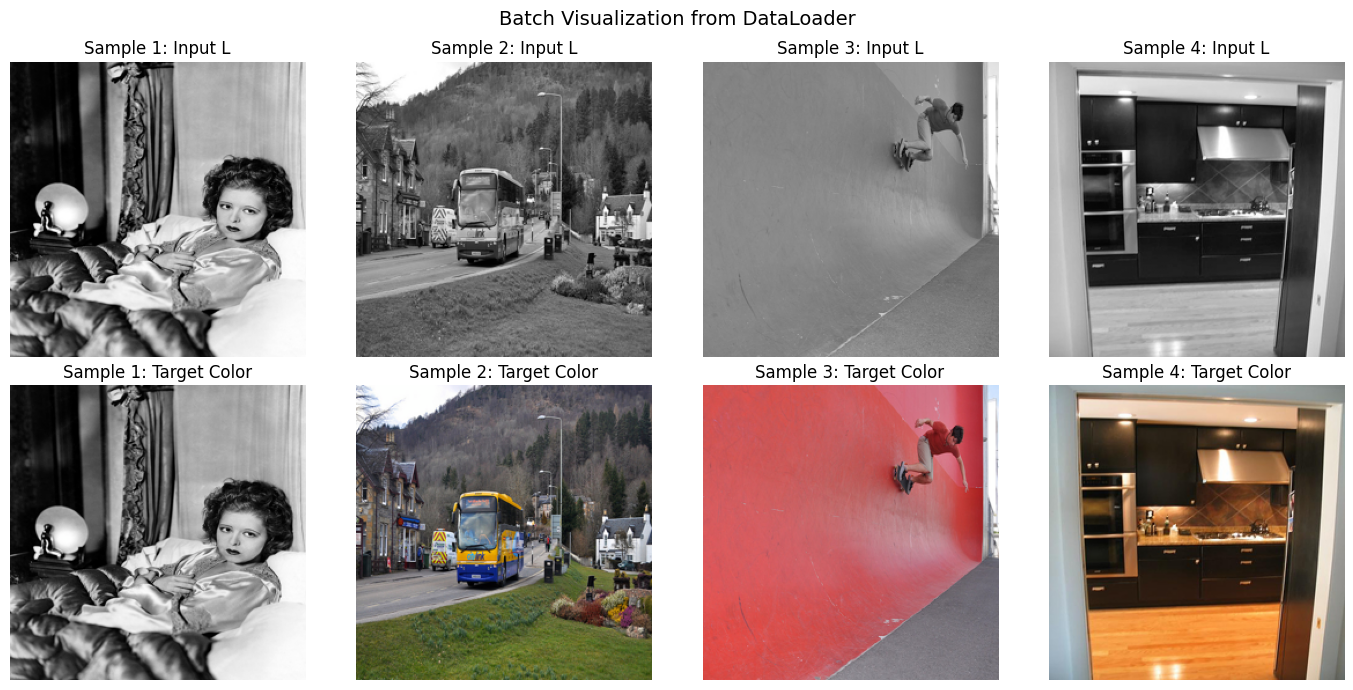

In [7]:
def lab_to_rgb(L_tensor, ab_tensor):
    """
    Converts normalized L (1, H, W) and ab (2, H, W) tensors back to RGB [0, 1].
    """
    L_np = L_tensor.squeeze().detach().cpu().numpy()
    ab_np = ab_tensor.detach().cpu().numpy().transpose(1, 2, 0)
    
    L_denorm = (L_np + 1.0) * 50.0
    ab_denorm = ab_np * 128.0
    
    H, W = L_np.shape
    lab = np.zeros((H, W, 3), dtype=np.float64)
    lab[:, :, 0] = L_denorm
    lab[:, :, 1:] = ab_denorm
    
    rgb = color.lab2rgb(lab)
    return np.clip(rgb, 0.0, 1.0)

# Display 4 images from the batch
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    l_img = batch_L[i]
    ab_img = batch_ab[i]
    rgb_reconstructed = lab_to_rgb(l_img, ab_img)
    
    # Row 1: Grayscale input
    axes[0, i].imshow(l_img.squeeze(), cmap="gray")
    axes[0, i].set_title(f"Sample {i+1}: Input L")
    axes[0, i].axis("off")
    
    # Row 2: Target color image
    axes[1, i].imshow(rgb_reconstructed)
    axes[1, i].set_title(f"Sample {i+1}: Target Color")
    axes[1, i].axis("off")

plt.suptitle("Batch Visualization from DataLoader", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

### 8. Benchmark Data Loading Speed
Let's see how fast our DataLoader streams images to ensure our GPU will never be starved of data during training:

In [8]:
start_time = time.time()
num_test_batches = 10

for i, b in enumerate(train_loader):
    _ = b["L"].to(device, non_blocking=True)
    _ = b["ab"].to(device, non_blocking=True)
    if i + 1 == num_test_batches:
        break

elapsed = time.time() - start_time
fps = (num_test_batches * BATCH_SIZE) / elapsed
print(f"Streamed {num_test_batches * BATCH_SIZE} images in {elapsed:.2f} seconds ({fps:.1f} images/sec)!")

Streamed 160 images in 2.33 seconds (68.7 images/sec)!


### Summary & Next Step

- We have a robust, high-speed `ColorizationDataset` and `DataLoader`.
- Input shapes: `(16, 1, 256, 256)` $\to$ Grayscale.
- Target shapes: `(16, 2, 256, 256)` $\to$ Color hues.

👉 **Next Notebook:** `03_model_architecture.ipynb` where we build the neural network (U-Net with ResNet backbone)!